# Transformer encoder baseline (Stage 1) — Alden

Joint intent classification + slot filling with a Transformer encoder trained from scratch on top of GloVe word vectors.

Cells under **Shared pipeline** are copied verbatim from `main.ipynb` (data loading, BIOES tagging, decoding, evaluation),
so the scores here use exactly the same scoring rules as every other model.

## Shared pipeline (copied from main.ipynb)

imports and global vars

In [1]:
import json, re
from collections import Counter
import numpy as np
import nltk
import os

import torch
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.nn.utils import clip_grad_norm_
from torch.utils import data
from torch.utils.data import DataLoader, Dataset

import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../Data/data/en-US.jsonl"
SLOT_REGEX = re.compile(r"\[([^\[\]:]+)\s*:\s*([^\[\]]+)\]")
UNK_TOKEN = "<UNK>"
PAD_TOKEN = "<PAD>"
HIDDEN_SIZE = 128
NUM_EPOCHS = 100
BATCH_SIZE = 50
LEARNING_RATE = 0.01
EMBEDDING_DIM = 100  # glove embedding are usually 50,100,200,300
SAVE_DIR = "../Results/"

load dataset functions

In [2]:
def parse_slots(annot_utt):
    # get list of (slot_type, slot_span) from annot_utt
    # turns the [color_type : pink] into ("color_type", "pink")
    return [(t.strip(), s.strip()) for t, s in SLOT_REGEX.findall(annot_utt)]

def load_massive(path=DATA_PATH):
    splits = {"train": [], "dev": [], "test": []}
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            splits[r["partition"]].append({
                "id": r["id"],
                "scenario": r["scenario"],
                "intent": r["intent"],
                "utt": r["utt"],
                "annot_utt": r["annot_utt"],
                "slots": parse_slots(r["annot_utt"]),  
            })
    return splits

split the dataset

In [3]:
splits = load_massive()
expected = {"train": 11514, "dev": 2033, "test": 2974}
for k, n in expected.items():
    print(f"{k}: {len(splits[k])}")
    assert len(splits[k]) == n
assert sum(len(v) for v in splits.values()) == 16521

intents = sorted({r["intent"] for v in splits.values() for r in v})
slotTypes = sorted({t for v in splits.values() for r in v for t, _ in r["slots"]})
print("intents:", len(intents), "| slot types:", len(slotTypes))
print(splits["train"][1])

train: 11514
dev: 2033
test: 2974
intents: 60 | slot types: 55
{'id': '2', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'set an alarm for two hours from now', 'annot_utt': 'set an alarm for [time : two hours from now]', 'slots': [('time', 'two hours from now')]}


preprocessing data

going with BIOES tagging for the parts of the sentence

In [4]:
def annot_to_bioes(annot_utt):
    """Convert annotated text into tokens and BIOES tags."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell

    tokens = []
    tags = []
    position = 0

    # Process each annotated slot, such as [time : five am]
    for match in SLOT_REGEX.finditer(annot_utt):

        # Words outside a slot are tagged as O
        outsideText = annot_utt[position:match.start()]

        for word in outsideText.split():
            tokens.append(word)
            tags.append("O")

        slotType = match.group(1).strip()
        words = match.group(2).split()

        # Assign BIOES tag for each word 
        for i, word in enumerate(words):
            if len(words) == 1:
                tag = f"S-{slotType}"
            elif i == 0:
                tag = f"B-{slotType}"
            elif i == len(words) - 1:
                tag = f"E-{slotType}"
            else:
                tag = f"I-{slotType}"

            tokens.append(word)
            tags.append(tag)

        position = match.end()

    # Process any remaining words after the last slot
    for word in annot_utt[position:].split():
        tokens.append(word)
        tags.append("O")

    return tokens, tags


def build_tag_vocab(records):

    slotTypes = sorted({
        slotType
        for record in records
        for slotType, _ in record["slots"]
    })

    tags = ["O"]

    for slotType in slotTypes:
        for prefix in ("B", "I", "E", "S"):
            tags.append(f"{prefix}-{slotType}")

    tagToId = {tag: i for i, tag in enumerate(tags)}

    return tags, tagToId

Decode the BIOES tags into (slot_type, slot_span)

In [5]:
def decode_bioes(tokens, tags):
    """Convert BIOES tags into a list of (slotType, slotSpan) pairs."""

    spans = []
    currentType = None
    currentTokens = []

    def closeSpan():
        nonlocal currentType, currentTokens

        if currentType is not None:
            slotText = " ".join(currentTokens)
            spans.append((currentType, slotText))

        currentType = None
        currentTokens = []

    for token, tag in zip(tokens, tags):

        if tag == "O":
            closeSpan()
            continue

        prefix, slotType = tag.split("-", 1)

        if prefix == "B":
            closeSpan()
            currentType = slotType
            currentTokens = [token]

        elif prefix == "I":
            if currentType == slotType:
                currentTokens.append(token)
            else:
                closeSpan()
                currentType = slotType
                currentTokens = [token]

        elif prefix == "E":
            if currentType == slotType:
                currentTokens.append(token)
                closeSpan()
            else:
                closeSpan()
                spans.append((slotType, token))

        elif prefix == "S":
            closeSpan()
            spans.append((slotType, token))

        else:
            closeSpan()

    # Include any unfinished span at the end
    closeSpan()

    return spans

Evaluation functions

In [6]:
def eval_intent_accuracy(actual, predicted):
    """Calculate the percentage of correctly predicted intents."""

    assert len(actual) == len(predicted)

    correctCount = sum(
        gold == pred
        for gold, pred in zip(actual, predicted)
    )

    return 100.0 * correctCount / len(actual)

def eval_macro_f1(actual, predicted):
    """Calculate micro F1 for slot types and spans across all utterances."""

    assert len(actual) == len(predicted)

    truePositives = 0
    falsePositives = 0
    falseNegatives = 0

    for act, pred in zip(actual, predicted):
        actualCount = Counter(act)
        predCount= Counter(pred)

        matchedCount = sum((actualCount & predCount).values())

        truePositives += matchedCount
        falsePositives += sum(predCount.values()) - matchedCount
        falseNegatives += sum(actualCount.values()) - matchedCount

    denominator = (
        2 * truePositives
        + falsePositives
        + falseNegatives
    )

    if denominator == 0:
        return 0.0

    return 100.0 * 2 * truePositives / denominator

def evaluate(goldIntents, predIntents, goldSlots, predSlots):
    """Calculate and return intent accuracy and slot F1."""

    intentAcc = round(eval_intent_accuracy(goldIntents, predIntents), 2)

    slotF1 = round(eval_macro_f1(goldSlots, predSlots), 2)

    return {
        "intent_acc": intentAcc,
        "slot_f1": slotF1,
    }

## Transformer-specific setup

GloVe: download `glove.6B.zip` from https://nlp.stanford.edu/projects/glove/ and put `glove.6B.300d.txt` in `Data/glove/`
(the folder is git-ignored). The word2vec-format file with a `400000 300` header line also works.

In [7]:
import math, time, random
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
GLOVE_PATH = "../Data/glove/glove.6B.300d.txt"
GLOVE_DIM = 300

# model
D_MODEL = 256
N_HEADS = 4
N_LAYERS = 3
FF_DIM = 512
DROPOUT = 0.1
MAX_LEN = 64  # longest utterance in MASSIVE en-US is 61 tokens

# training
TF_EPOCHS = 50
TF_BATCH_SIZE = 32
TF_LR = 5e-4
WEIGHT_DECAY = 0.01
WARMUP_EPOCHS = 2
PATIENCE = 10
CLIP_NORM = 1.0
CKPT_PATH = os.path.join(SAVE_DIR, "transformer_baseline_best.pt")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
os.makedirs(SAVE_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


### Vocabularies

Word vocab is built from the **training split only**. Words not in it map to `<UNK>`.
The model input is `utt` only; `annot_utt` is used only to build the gold BIOES tags
(`utt.split()` and the tokens recovered from `annot_utt` line up exactly for every record, checked below).

In [8]:
for split in splits.values():
    for r in split:
        r["tokens"], r["tags"] = annot_to_bioes(r["annot_utt"])
        assert r["tokens"] == r["utt"].split(), r["id"]

wordCounts = Counter(tok for r in splits["train"] for tok in r["tokens"])
idToWord = [PAD_TOKEN, UNK_TOKEN] + sorted(wordCounts)
wordToId = {w: i for i, w in enumerate(idToWord)}

idToTag, tagToId = build_tag_vocab(splits["train"])
idToIntent = sorted({r["intent"] for r in splits["train"]})
intentToId = {it: i for i, it in enumerate(idToIntent)}

print("words:", len(idToWord), "| tags:", len(idToTag), "| intents:", len(idToIntent))
for k in ("dev", "test"):
    toks = [t for r in splits[k] for t in r["tokens"]]
    oov = sum(t not in wordToId for t in toks)
    print(f"{k} OOV rate: {100 * oov / len(toks):.2f}%")

words: 5304 | tags: 221 | intents: 60
dev OOV rate: 3.32%
test OOV rate: 3.51%


### GloVe embedding matrix (only rows for the training vocab, to keep the parameter count small)

In [9]:
def load_glove(path, vocab, dim):
    matrix = np.random.normal(0, 0.1, (len(vocab), dim)).astype(np.float32)
    matrix[0] = 0  # <PAD>
    found = 0
    if not os.path.exists(path):
        print(f"WARNING: {path} not found, using random embeddings")
        return torch.tensor(matrix), found
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            if len(parts) != dim + 1:
                continue  # header line of word2vec-format files
            idx = vocab.get(parts[0])
            if idx is not None:
                matrix[idx] = np.asarray(parts[1:], dtype=np.float32)
                found += 1
    return torch.tensor(matrix), found

embMatrix, gloveFound = load_glove(GLOVE_PATH, wordToId, GLOVE_DIM)
print(f"GloVe coverage: {gloveFound}/{len(idToWord) - 2} training words")

GloVe coverage: 0/5302 training words


### Dataset and batching

In [10]:
class MassiveDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        tokenIds = torch.tensor([wordToId.get(t, 1) for t in r["tokens"]])
        tagIds = torch.tensor([tagToId[t] for t in r["tags"]])
        return tokenIds, tagIds, intentToId[r["intent"]]

def collate(batch):
    tokenIds, tagIds, intentIds = zip(*batch)
    tokens = pad_sequence(tokenIds, batch_first=True, padding_value=0)
    tags = pad_sequence(tagIds, batch_first=True, padding_value=-100)  # ignored by the loss
    return tokens, tags, torch.tensor(intentIds)

loaderGen = torch.Generator().manual_seed(SEED)
trainLoader = DataLoader(MassiveDataset(splits["train"]), batch_size=TF_BATCH_SIZE, shuffle=True,
                         collate_fn=collate, generator=loaderGen)
devLoader = DataLoader(MassiveDataset(splits["dev"]), batch_size=128, collate_fn=collate)
testLoader = DataLoader(MassiveDataset(splits["test"]), batch_size=128, collate_fn=collate)

### Model

- **Input**: word ids of `utt` (whitespace tokens), padded per batch.
- **Embedding**: GloVe 300d (fine-tuned), linearly projected to `D_MODEL`, plus learned position embeddings.
  A learnable `[CLS]` vector is prepended to the sequence.
- **Encoder**: `N_LAYERS` pre-LayerNorm Transformer encoder layers (multi-head self-attention + GELU feed-forward),
  padding positions masked out of attention.
- **Outputs** (one joint network, shared encoder):
  - intent logits from the `[CLS]` position (60 classes)
  - per-token BIOES slot-tag logits (1 + 4×55 = 221 tags), decoded to `[slot type: slot span]` pairs with `decode_bioes`
- **Loss**: cross-entropy(intent) + token-level cross-entropy(slot tags), padding ignored.
- **Optimiser**: AdamW, linear warm-up for `WARMUP_EPOCHS` then cosine decay, gradient clipping at 1.0.

In [11]:
class JointTransformer(nn.Module):
    def __init__(self, embMatrix, numIntents, numTags, dModel=D_MODEL, nHeads=N_HEADS,
                 nLayers=N_LAYERS, ffDim=FF_DIM, dropout=DROPOUT, maxLen=MAX_LEN):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(embMatrix, freeze=False, padding_idx=0)
        self.embProj = nn.Linear(embMatrix.size(1), dModel)
        self.cls = nn.Parameter(torch.randn(1, 1, dModel) * 0.02)
        self.posEmb = nn.Embedding(maxLen + 1, dModel)  # +1 for [CLS]
        self.embDropout = nn.Dropout(dropout)

        layer = nn.TransformerEncoderLayer(dModel, nHeads, ffDim, dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, nLayers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dModel)

        self.intentHead = nn.Sequential(nn.Dropout(dropout), nn.Linear(dModel, numIntents))
        self.slotHead = nn.Sequential(nn.Dropout(dropout), nn.Linear(dModel, numTags))

    def forward(self, tokens):
        padMask = tokens == 0
        x = self.embProj(self.embedding(tokens))
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], dim=1)
        positions = torch.arange(x.size(1), device=tokens.device)
        x = self.embDropout(x + self.posEmb(positions))

        clsMask = torch.zeros(tokens.size(0), 1, dtype=torch.bool, device=tokens.device)
        h = self.encoder(x, src_key_padding_mask=torch.cat([clsMask, padMask], dim=1))
        h = self.norm(h)

        return self.intentHead(h[:, 0]), self.slotHead(h[:, 1:])

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

set_seed()
model = JointTransformer(embMatrix, len(idToIntent), len(idToTag)).to(device)
totalParams, trainableParams = count_params(model)
print(model)
print(f"Total parameters: {totalParams:,} | trainable: {trainableParams:,} "
      f"(of which word embeddings: {model.embedding.weight.numel():,})")
assert totalParams <= 20_000_000

JointTransformer(
  (embedding): Embedding(5304, 300, padding_idx=0)
  (embProj): Linear(in_features=300, out_features=256, bias=True)
  (posEmb): Embedding(65, 256)
  (embDropout): Dropout(p=0.1, inplace=False)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=Tru

### Training / evaluation loop

In [12]:
def joint_loss(intentLogits, slotLogits, intentIds, tagIds):
    intentLoss = F.cross_entropy(intentLogits, intentIds)
    slotLoss = F.cross_entropy(slotLogits.reshape(-1, slotLogits.size(-1)), tagIds.reshape(-1), ignore_index=-100)
    return intentLoss + slotLoss

@torch.no_grad()
def run_eval(model, loader, records):
    """Return average loss, metrics, and predictions (intents, slot pairs) for one split."""
    model.eval()
    totalLoss, predIntents, predSlots = 0.0, [], []
    i = 0
    for tokens, tags, intentIds in loader:
        tokens, tags, intentIds = tokens.to(device), tags.to(device), intentIds.to(device)
        intentLogits, slotLogits = model(tokens)
        totalLoss += joint_loss(intentLogits, slotLogits, intentIds, tags).item() * tokens.size(0)

        for intentId, tagSeq in zip(intentLogits.argmax(-1).tolist(), slotLogits.argmax(-1).tolist()):
            r = records[i]
            predTags = [idToTag[t] for t in tagSeq[:len(r["tokens"])]]
            predIntents.append(idToIntent[intentId])
            predSlots.append(decode_bioes(r["tokens"], predTags))
            i += 1

    metrics = evaluate([r["intent"] for r in records], predIntents, [r["slots"] for r in records], predSlots)
    metrics["combined"] = round((metrics["intent_acc"] + metrics["slot_f1"]) / 2, 2)
    return totalLoss / len(records), metrics, predIntents, predSlots

def lr_lambda(step, stepsPerEpoch=len(trainLoader)):
    warmup = WARMUP_EPOCHS * stepsPerEpoch
    total = TF_EPOCHS * stepsPerEpoch
    if step < warmup:
        return (step + 1) / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))

### Train and select the baseline checkpoint

Model selection uses the **combined** validation score = mean(intent accuracy, slot micro F1).
Training stops early if the combined score has not improved for `PATIENCE` epochs.

In [13]:
set_seed()
model = JointTransformer(embMatrix, len(idToIntent), len(idToTag)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=TF_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

history = []
bestScore, bestEpoch, badEpochs = -1.0, -1, 0
startTime = time.time()

for epoch in range(1, TF_EPOCHS + 1):
    model.train()
    epochStart, trainLoss = time.time(), 0.0
    for tokens, tags, intentIds in trainLoader:
        tokens, tags, intentIds = tokens.to(device), tags.to(device), intentIds.to(device)
        intentLogits, slotLogits = model(tokens)
        loss = joint_loss(intentLogits, slotLogits, intentIds, tags)

        optimizer.zero_grad()
        loss.backward()
        clip_grad_norm_(model.parameters(), CLIP_NORM)
        optimizer.step()
        scheduler.step()
        trainLoss += loss.item() * tokens.size(0)
    trainLoss /= len(splits["train"])

    devLoss, devMetrics, _, _ = run_eval(model, devLoader, splits["dev"])
    elapsed = time.time() - epochStart
    history.append({"epoch": epoch, "train_loss": trainLoss, "dev_loss": devLoss, **devMetrics, "time_s": elapsed})

    improved = devMetrics["combined"] > bestScore
    if improved:
        bestScore, bestEpoch, badEpochs = devMetrics["combined"], epoch, 0
        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "dev_metrics": devMetrics,
            "idToWord": idToWord, "idToTag": idToTag, "idToIntent": idToIntent,
        }, CKPT_PATH)
    else:
        badEpochs += 1

    print(f"epoch {epoch:2d} | train loss {trainLoss:.4f} | dev loss {devLoss:.4f} | "
          f"dev intent acc {devMetrics['intent_acc']:.2f} | dev slot F1 {devMetrics['slot_f1']:.2f} | "
          f"combined {devMetrics['combined']:.2f} | {elapsed:.1f}s" + (" *" if improved else ""))

    if badEpochs >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs")
        break

print(f"\nTotal training time: {time.time() - startTime:.1f}s")
print(f"Best epoch: {bestEpoch} | best dev combined score: {bestScore:.2f} | checkpoint: {CKPT_PATH}")

epoch  1 | train loss 5.8410 | dev loss 4.8817 | dev intent acc 13.72 | dev slot F1 4.74 | combined 9.23 | 87.4s *
epoch  2 | train loss 3.7951 | dev loss 2.5353 | dev intent acc 57.65 | dev slot F1 29.17 | combined 43.41 | 84.3s *
epoch  3 | train loss 2.0897 | dev loss 1.6956 | dev intent acc 73.64 | dev slot F1 43.27 | combined 58.45 | 83.8s *
epoch  4 | train loss 1.3933 | dev loss 1.4282 | dev intent acc 77.82 | dev slot F1 51.06 | combined 64.44 | 86.9s *
epoch  5 | train loss 1.0452 | dev loss 1.3569 | dev intent acc 80.47 | dev slot F1 56.13 | combined 68.30 | 92.7s *
epoch  6 | train loss 0.8392 | dev loss 1.3916 | dev intent acc 79.59 | dev slot F1 60.92 | combined 70.25 | 96.2s *
epoch  7 | train loss 0.7022 | dev loss 1.3227 | dev intent acc 81.21 | dev slot F1 63.39 | combined 72.30 | 84.6s *
epoch  8 | train loss 0.5979 | dev loss 1.3353 | dev intent acc 81.41 | dev slot F1 65.99 | combined 73.70 | 103.6s *
epoch  9 | train loss 0.5155 | dev loss 1.3814 | dev intent acc 8

### Learning curves

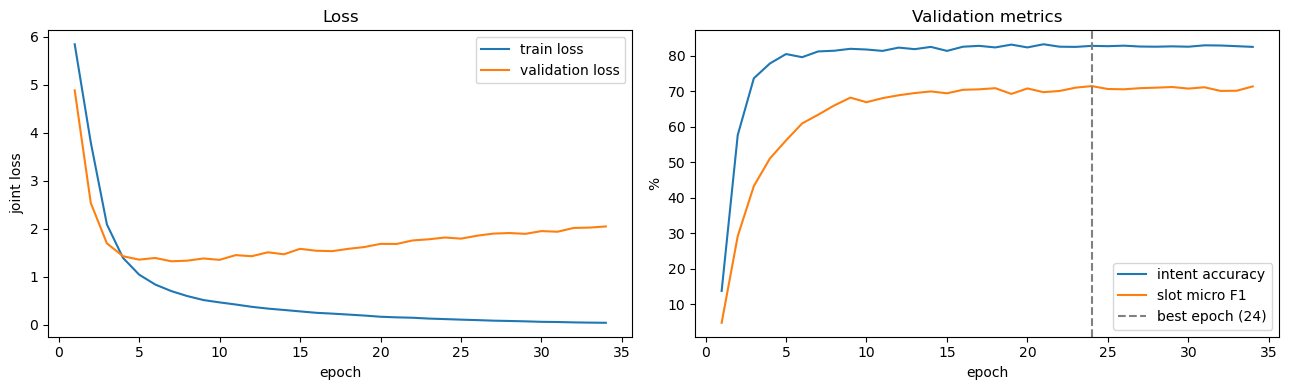

In [14]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, [h["train_loss"] for h in history], label="train loss")
axes[0].plot(epochs, [h["dev_loss"] for h in history], label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("joint loss"); axes[0].legend(); axes[0].set_title("Loss")

axes[1].plot(epochs, [h["intent_acc"] for h in history], label="intent accuracy")
axes[1].plot(epochs, [h["slot_f1"] for h in history], label="slot micro F1")
axes[1].axvline(bestEpoch, color="grey", linestyle="--", label=f"best epoch ({bestEpoch})")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].legend(); axes[1].set_title("Validation metrics")

plt.tight_layout()
plt.show()

### Final evaluation of the baseline checkpoint

Load the saved checkpoint and evaluate without any further training.
The validation score must match the best score printed during training.

In [15]:
ckpt = torch.load(CKPT_PATH, map_location=device)
finalModel = JointTransformer(embMatrix, len(idToIntent), len(idToTag)).to(device)
finalModel.load_state_dict(ckpt["model_state"])
print(f"Loaded {CKPT_PATH} (epoch {ckpt['epoch']})")

_, devFinal, _, _ = run_eval(finalModel, devLoader, splits["dev"])
_, testFinal, testIntents, testSlots = run_eval(finalModel, testLoader, splits["test"])
assert devFinal["combined"] == bestScore, (devFinal, bestScore)

total, trainable = count_params(finalModel)
print(f"Total parameters: {total:,} | trainable: {trainable:,} | epochs trained: {len(history)} (best: {ckpt['epoch']})")
print(f"Validation | intent accuracy: {devFinal['intent_acc']:.2f}% | slot micro F1: {devFinal['slot_f1']:.2f}%")
print(f"Test       | intent accuracy: {testFinal['intent_acc']:.2f}% | slot micro F1: {testFinal['slot_f1']:.2f}%")

Loaded ../Results/transformer_baseline_best.pt (epoch 24)
Total parameters: 3,339,193 | trainable: 3,339,193 | epochs trained: 34 (best: 24)
Validation | intent accuracy: 82.78% | slot micro F1: 71.44%
Test       | intent accuracy: 81.14% | slot micro F1: 67.63%


### Error analysis (test set)

In [16]:
intentErrors = Counter((r["intent"], p) for r, p in zip(splits["test"], testIntents) if r["intent"] != p)
print("Most frequent intent confusions (gold -> predicted):")
for (gold, pred), n in intentErrors.most_common(10):
    print(f"  {n:3d}  {gold} -> {pred}")

slotFN, slotFP = Counter(), Counter()
for r, pred in zip(splits["test"], testSlots):
    gold, predC = Counter(r["slots"]), Counter(pred)
    slotFN.update(t for t, _ in (gold - predC).elements())
    slotFP.update(t for t, _ in (predC - gold).elements())
print("\nSlot types with most misses (FN) / spurious predictions (FP):")
for t, n in slotFN.most_common(10):
    print(f"  {t:20s} FN={n:3d} FP={slotFP[t]:3d}")

print("\nSample wrong predictions:")
shown = 0
for r, pi, ps in zip(splits["test"], testIntents, testSlots):
    if pi != r["intent"] or Counter(ps) != Counter(r["slots"]):
        print(f"  utt:  {r['utt']}\n  gold: {r['intent']} {r['slots']}\n  pred: {pi} {ps}\n")
        shown += 1
        if shown == 8:
            break

Most frequent intent confusions (gold -> predicted):
   21  general_quirky -> qa_factoid
   15  qa_factoid -> general_quirky
   10  general_quirky -> news_query
    9  general_quirky -> calendar_set
    8  calendar_query -> calendar_set
    8  qa_definition -> general_quirky
    7  general_quirky -> calendar_query
    6  calendar_query -> general_quirky
    6  email_query -> email_sendemail
    5  play_music -> play_audiobook

Slot types with most misses (FN) / spurious predictions (FP):
  place_name           FN= 99 FP= 74
  event_name           FN= 91 FP= 94
  person               FN= 76 FP= 59
  time                 FN= 55 FP= 73
  date                 FN= 50 FP= 97
  business_name        FN= 46 FP= 29
  food_type            FN= 32 FP= 47
  news_topic           FN= 31 FP= 23
  artist_name          FN= 30 FP= 14
  media_type           FN= 26 FP= 24

Sample wrong predictions:
  utt:  pink is all we need
  gold: iot_hue_lightchange [('color_type', 'pink')]
  pred: play_music [('artist_